# Function to automatic merge and fill missing values



## Create the function
You have to create a function which take 2 arguments :
- argument 1 : DataFrame main
- argument 2 : DataFrame opinion

Your function will return a new DataFrame which is the left merge of both DataFrames, and which has no missing values (so your function has to fill them), add new columns (flag, MONTH and DAY), and OPINION should be translated.

So you have to copy each useful code from the previous quests, and integrate it into a function. **This should achieve the same results as the previous quests.**

In [29]:
import pandas as pd

In [30]:
# Chargement des Datasets

link_main = "https://raw.githubusercontent.com/murpi/wilddata/master/quests/weather_main_2018.csv"
link_opinion = "https://raw.githubusercontent.com/murpi/wilddata/master/quests/weather_opinion_2018.csv"
df_main = pd.read_csv(link_main)
df_opinion = pd.read_csv(link_opinion)


In [31]:
# Affichage des premières lignes de df_main
df_main.head()


,DATE,MAX_TEMPERATURE_C,MIN_TEMPERATURE_C,WINDSPEED_MAX_KMH,TEMPERATURE_MORNING_C,TEMPERATURE_NOON_C,TEMPERATURE_EVENING_C,PRECIP_TOTAL_DAY_MM,HUMIDITY_MAX_PERCENT,VISIBILITY_AVG_KM,PRESSURE_MAX_MB,CLOUDCOVER_AVG_PERCENT,HEATINDEX_MAX_C,DEWPOINT_MAX_C,WINDTEMP_MAX_C
0,2018-01-01,12,8,61,9,11,8,8.9,79,9.500,1018,41.750,12,8,7
1,2018-01-02,13,6,26,8,12,13,0.6,96,9.000,1020,87.875,13,12,6
2,2018-01-03,15,10,40,11,12,10,5.5,82,8.500,1017,91.500,15,13,7
3,2018-01-04,14,11,45,14,14,11,0.0,89,10.000,1011,90.125,14,12,10
4,2018-01-05,12,7,21,10,11,8,1.5,85,9.875,1005,62.375,12,10,7


In [32]:
# Affichage des premières lignes de df_opinion
df_opinion.head()

,date,WEATHER_CODE_EVENING,TOTAL_SNOW_MM,UV_INDEX,SUNHOUR,OPINION
0,2018-01-01,113,0,3,5.1,bad
1,2018-03-12,119,0,2,8.8,bad
2,2018-03-09,116,0,3,10.2,bad
3,2018-10-07,122,0,1,5.6,bad
4,2018-06-18,119,0,1,12.9,bad


In [33]:
# Affichage du nombre de lignes et de colonnes de df_main
df_main.shape

(365, 15)

In [34]:
# Affichage des informations de df_main
df_main.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   DATE                    365 non-null    object 
 1   MAX_TEMPERATURE_C       365 non-null    int64  
 2   MIN_TEMPERATURE_C       365 non-null    int64  
 3   WINDSPEED_MAX_KMH       365 non-null    int64  
 4   TEMPERATURE_MORNING_C   365 non-null    int64  
 5   TEMPERATURE_NOON_C      365 non-null    int64  
 6   TEMPERATURE_EVENING_C   365 non-null    int64  
 7   PRECIP_TOTAL_DAY_MM     365 non-null    float64
 8   HUMIDITY_MAX_PERCENT    365 non-null    int64  
 9   VISIBILITY_AVG_KM       365 non-null    float64
 10  PRESSURE_MAX_MB         365 non-null    int64  
 11  CLOUDCOVER_AVG_PERCENT  365 non-null    float64
 12  HEATINDEX_MAX_C         365 non-null    int64  
 13  DEWPOINT_MAX_C          365 non-null    int64  
 14  WINDTEMP_MAX_C          365 non-null    in

In [35]:
# Nombre de valeurs nulles de df_main
df_main.isna().sum()

DATE                      0
MAX_TEMPERATURE_C         0
MIN_TEMPERATURE_C         0
WINDSPEED_MAX_KMH         0
TEMPERATURE_MORNING_C     0
TEMPERATURE_NOON_C        0
TEMPERATURE_EVENING_C     0
PRECIP_TOTAL_DAY_MM       0
HUMIDITY_MAX_PERCENT      0
VISIBILITY_AVG_KM         0
PRESSURE_MAX_MB           0
CLOUDCOVER_AVG_PERCENT    0
HEATINDEX_MAX_C           0
DEWPOINT_MAX_C            0
WINDTEMP_MAX_C            0
dtype: int64

In [36]:
# Nombre de lignes et de colonnes de df_opinion
df_opinion.shape

(341, 6)

In [37]:
# Nombre de valeurs nulles de df_opinion
df_opinion.isna().sum()

date                    0
WEATHER_CODE_EVENING    0
TOTAL_SNOW_MM           0
UV_INDEX                0
SUNHOUR                 0
OPINION                 0
dtype: int64

In [38]:
# Création d'une fonction merge_and_fill qui prend en paramètre
# deux DataFrame pour les joindre avec un left join sur la colonne de date

from datetime import datetime

def merge_and_fill(DataFrameMain, DataFrameOpinion):

  # MERGE BOTH DATAFRAMES
  NewDataFrame =  pd.merge(
                  DataFrameMain,
                  DataFrameOpinion,
                  how="left",
                  left_on= DataFrameMain.columns[0],
                  right_on= DataFrameOpinion.columns[0])
   # Ajout de la colonne FLAG pour OPINION nulles
  NewDataFrame["FLAG"] = NewDataFrame["OPINION"].isna().sum()

  # DROP COLUMN date
  NewDataFrame = NewDataFrame.drop("date", axis = 1)

  # FILL IN MISSING VALUES
  # WEATHER_CODE_EVENING => mode
  NewDataFrame["WEATHER_CODE_EVENING"] = NewDataFrame["WEATHER_CODE_EVENING"].fillna(NewDataFrame["WEATHER_CODE_EVENING"].mode()[0])

  # TOTAL_SNOW_MM => moyenne
  NewDataFrame["TOTAL_SNOW_MM"] = NewDataFrame["TOTAL_SNOW_MM"].fillna(NewDataFrame["TOTAL_SNOW_MM"].mean())

  # UV_INDEX => médiane
  NewDataFrame["UV_INDEX"] = NewDataFrame["UV_INDEX"].fillna(NewDataFrame["UV_INDEX"].median())

  # SUNHOUR => bfill
  NewDataFrame["SUNHOUR"] = NewDataFrame["SUNHOUR"].bfill()

  # OPINION => remplacer les nuls par "Unknown"
  NewDataFrame["OPINION"] = NewDataFrame["OPINION"].fillna("unknown")

  # Conversion de la colonne DATE au format Datetime
  NewDataFrame["DATE"] = pd.to_datetime(NewDataFrame["DATE"])

  # Création de la colonne MONTH
  NewDataFrame["MONTH"] = NewDataFrame["DATE"].dt.month

  # Création de la colonne DAY
  NewDataFrame["DAY"] = NewDataFrame["DATE"].dt.day

  # Tradudction de la colonne OPINION en français (créer une fonction)
  def traduction(opinion):
    mapping = { "bad": "mauvais",
                "good": "bon",
                "not good not bad": "moyen",
                "very bad" : "très mauvais",
                "very good" : "très bon",
                "unknown": "inconnu"}
    return opinion.map(mapping)
  NewDataFrame["OPINION"] = traduction(NewDataFrame["OPINION"])
  # Return new merged dataframe
  return NewDataFrame

In [39]:
df_2018 = merge_and_fill(df_main, df_opinion)

In [40]:
# Afficher le nombre de lignes et de colonnes de df_2018
# Afficher les premières ignes de df_2018
print(df_2018.shape)
df_2018.head(5)

(365, 23)


,DATE,MAX_TEMPERATURE_C,MIN_TEMPERATURE_C,WINDSPEED_MAX_KMH,TEMPERATURE_MORNING_C,TEMPERATURE_NOON_C,TEMPERATURE_EVENING_C,PRECIP_TOTAL_DAY_MM,HUMIDITY_MAX_PERCENT,VISIBILITY_AVG_KM,...,DEWPOINT_MAX_C,WINDTEMP_MAX_C,WEATHER_CODE_EVENING,TOTAL_SNOW_MM,UV_INDEX,SUNHOUR,OPINION,FLAG,MONTH,DAY
0,2018-01-01,12,8,61,9,11,8,8.9,79,9.500,...,8,7,113.0,0.0,3.0,5.1,mauvais,24,1,1
1,2018-01-02,13,6,26,8,12,13,0.6,96,9.000,...,12,6,122.0,0.0,3.0,3.3,mauvais,24,1,2
2,2018-01-03,15,10,40,11,12,10,5.5,82,8.500,...,13,7,122.0,0.0,3.0,3.3,mauvais,24,1,3
3,2018-01-04,14,11,45,14,14,11,0.0,89,10.000,...,12,10,116.0,0.0,3.0,3.3,mauvais,24,1,4
4,2018-01-05,12,7,21,10,11,8,1.5,85,9.875,...,10,7,116.0,0.0,3.0,6.9,mauvais,24,1,5


In [41]:
# Afficher les informations de df_2018
df_2018.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   DATE                    365 non-null    datetime64[ns]
 1   MAX_TEMPERATURE_C       365 non-null    int64         
 2   MIN_TEMPERATURE_C       365 non-null    int64         
 3   WINDSPEED_MAX_KMH       365 non-null    int64         
 4   TEMPERATURE_MORNING_C   365 non-null    int64         
 5   TEMPERATURE_NOON_C      365 non-null    int64         
 6   TEMPERATURE_EVENING_C   365 non-null    int64         
 7   PRECIP_TOTAL_DAY_MM     365 non-null    float64       
 8   HUMIDITY_MAX_PERCENT    365 non-null    int64         
 9   VISIBILITY_AVG_KM       365 non-null    float64       
 10  PRESSURE_MAX_MB         365 non-null    int64         
 11  CLOUDCOVER_AVG_PERCENT  365 non-null    float64       
 12  HEATINDEX_MAX_C         365 non-null    int64     

## Execution with a loop
You will execute your function in a 9 rounds loop, once per year, and agregate this in a new big DataFrame with 24 columns and lots of rows.

In [42]:
# Chaque année entre 2010 et 2018 (inclus) a deux 2 sources : weather_main_YYYY.csv and weather_opinion_YYYY.csv
# Charger les deux datasets et joingez-les grâce à la fonction merge_and_fill
# Concaténez ce nouveau DataFrame au(x) précédent(s) pour n'obtenir qu'un long DataFrame df_weather

df_weather = pd.DataFrame()
# Créez la boucle :
for year in range(2010,2019):
      
      weather_main_YYYY= pd.read_csv(f"https://raw.githubusercontent.com/murpi/wilddata/master/quests/weather_main_{year}.csv")
      weather_opinion_YYYY= pd.read_csv(f"https://raw.githubusercontent.com/murpi/wilddata/master/quests/weather_opinion_{year}.csv")
      NewDataFrame =  pd.merge(
                  weather_main_YYYY,
                  weather_opinion_YYYY,
                  how="left",
                  left_on= weather_main_YYYY.columns[0],
                  right_on= weather_opinion_YYYY.columns[0])

      df_weather =  pd.concat([df_weather, NewDataFrame])
      


In [43]:
# Affichage des premières lignes de df_weather
df_weather.head()

,DATE,MAX_TEMPERATURE_C,MIN_TEMPERATURE_C,WINDSPEED_MAX_KMH,TEMPERATURE_MORNING_C,TEMPERATURE_NOON_C,TEMPERATURE_EVENING_C,PRECIP_TOTAL_DAY_MM,HUMIDITY_MAX_PERCENT,VISIBILITY_AVG_KM,...,CLOUDCOVER_AVG_PERCENT,HEATINDEX_MAX_C,DEWPOINT_MAX_C,WINDTEMP_MAX_C,date,WEATHER_CODE_EVENING,TOTAL_SNOW_MM,UV_INDEX,SUNHOUR,OPINION
0,2010-01-01,5,2,19,2,5,3,0.0,86,10.000,...,62.875,5,3,-1,2010-01-01,119.0,0.0,1.0,5.1,very bad
1,2010-01-02,5,-1,6,-1,4,1,0.0,78,10.000,...,31.375,5,0,2,2010-01-02,116.0,0.0,1.0,8.7,very bad
2,2010-01-03,5,1,26,2,4,2,0.3,61,9.875,...,65.500,5,0,-3,2010-01-03,119.0,0.0,1.0,6.9,very bad
3,2010-01-04,1,-4,25,-2,0,-3,0.0,75,10.000,...,9.875,1,0,-9,2010-01-04,113.0,0.0,1.0,8.7,very bad
4,2010-01-05,2,-5,20,-5,1,-4,0.0,71,10.000,...,8.000,3,0,-10,2010-01-05,113.0,0.0,1.0,8.7,very bad


In [44]:
df_weather.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3287 entries, 0 to 364
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   DATE                    3287 non-null   object 
 1   MAX_TEMPERATURE_C       3287 non-null   int64  
 2   MIN_TEMPERATURE_C       3287 non-null   int64  
 3   WINDSPEED_MAX_KMH       3287 non-null   int64  
 4   TEMPERATURE_MORNING_C   3287 non-null   int64  
 5   TEMPERATURE_NOON_C      3287 non-null   int64  
 6   TEMPERATURE_EVENING_C   3287 non-null   int64  
 7   PRECIP_TOTAL_DAY_MM     3287 non-null   float64
 8   HUMIDITY_MAX_PERCENT    3287 non-null   int64  
 9   VISIBILITY_AVG_KM       3287 non-null   float64
 10  PRESSURE_MAX_MB         3287 non-null   int64  
 11  CLOUDCOVER_AVG_PERCENT  3287 non-null   float64
 12  HEATINDEX_MAX_C         3287 non-null   int64  
 13  DEWPOINT_MAX_C          3287 non-null   int64  
 14  WINDTEMP_MAX_C          3287 non-null   int64 

In [45]:
# Création d'une fonction clean qui :
# * crée une colonne FLAG indiquant une valeur manquante
# * convertit la colonne DATE au format datetime
# * traduit l'opinion en français

def clean(DataFrameYear):

  DataFrameYear["FLAG"] = DataFrameYear["OPINION"].isna().sum()

  # FILL IN MISSING VALUES
  # WEATHER_CODE_EVENING => mode
  DataFrameYear["WEATHER_CODE_EVENING"] = DataFrameYear["WEATHER_CODE_EVENING"].fillna(DataFrameYear["WEATHER_CODE_EVENING"].mode()[0])

  # TOTAL_SNOW_MM => moyenne
  DataFrameYear["TOTAL_SNOW_MM"] = DataFrameYear["TOTAL_SNOW_MM"].fillna(DataFrameYear["TOTAL_SNOW_MM"].mean())

  # UV_INDEX => médiane
  DataFrameYear["UV_INDEX"] = DataFrameYear["UV_INDEX"].fillna(DataFrameYear["UV_INDEX"].median())

  # SUNHOUR => bfill
  DataFrameYear["SUNHOUR"] = DataFrameYear["SUNHOUR"].bfill()

  # OPINION => remplacer les nuls par "Unknown"
  DataFrameYear["OPINION"] = DataFrameYear["OPINION"].fillna("unknown")

  # Conversion de la colonne DATE au format Datetime
  DataFrameYear["DATE"] = pd.to_datetime(DataFrameYear["DATE"])

  # Création de la colonne MONTH
  DataFrameYear["MONTH"] = DataFrameYear["DATE"].dt.month

  # Création de la colonne DAY
  DataFrameYear["DAY"] = DataFrameYear["DATE"].dt.day

  # Tradudction de la colonne OPINION en français (créer une fonction)
  def traduction(opinion):
    mapping = { "bad": "mauvais",
                "good": "bon",
                "not good not bad": "moyen",
                "very bad" : "très mauvais",
                "very good" : "très bon",
                "unknown": "inconnu"}
    return opinion.map(mapping)
  NewDataFrame["OPINION"] = traduction(NewDataFrame["OPINION"])

    # DROP COLUMN date

  try:
    DataFrameYear = DataFrameYear.drop("date", axis=1)
  except KeyError:
    pass
  # Return new merged dataframe
  return DataFrameYear

clean(df_weather)

df_weather.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3287 entries, 0 to 364
Data columns (total 24 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   DATE                    3287 non-null   datetime64[ns]
 1   MAX_TEMPERATURE_C       3287 non-null   int64         
 2   MIN_TEMPERATURE_C       3287 non-null   int64         
 3   WINDSPEED_MAX_KMH       3287 non-null   int64         
 4   TEMPERATURE_MORNING_C   3287 non-null   int64         
 5   TEMPERATURE_NOON_C      3287 non-null   int64         
 6   TEMPERATURE_EVENING_C   3287 non-null   int64         
 7   PRECIP_TOTAL_DAY_MM     3287 non-null   float64       
 8   HUMIDITY_MAX_PERCENT    3287 non-null   int64         
 9   VISIBILITY_AVG_KM       3287 non-null   float64       
 10  PRESSURE_MAX_MB         3287 non-null   int64         
 11  CLOUDCOVER_AVG_PERCENT  3287 non-null   float64       
 12  HEATINDEX_MAX_C         3287 non-null   int64         

In [46]:
# On crée une liste de DataFrames pour les années 2019 à 2022 (inclus)

links = {}
for year in range(2019, 2023):
    # Collect both DataFrames each year
    year = str(year)
    links[year] = "https://raw.githubusercontent.com/WildCodeSchool/data-training-resources/main/quests/weather" + year + ".csv"

# Create dataframes from the links to clean
dfs = {}  # Dictionary to store dataframes
for year, link in links.items():
    dfs[year] = pd.read_csv(link)
    dfs[year] = clean(dfs[year])

dfs['2019']

,DATE,MAX_TEMPERATURE_C,MIN_TEMPERATURE_C,WINDSPEED_MAX_KMH,TEMPERATURE_MORNING_C,TEMPERATURE_NOON_C,TEMPERATURE_EVENING_C,PRECIP_TOTAL_DAY_MM,HUMIDITY_MAX_PERCENT,VISIBILITY_AVG_KM,...,WEATHER_CODE_MORNING,WEATHER_CODE_NOON,WEATHER_CODE_EVENING,TOTAL_SNOW_MM,UV_INDEX,SUNHOUR,OPINION,MONTH,DAY,FLAG
0,2019-01-01,9,4,10,4,7,8,0.2,94,9.000,...,116,143,176,0,1,5.1,very bad,1,1,0
1,2019-01-02,8,5,18,7,7,5,0.0,90,9.000,...,119,116,116,0,1,8.7,very bad,1,2,0
2,2019-01-03,6,0,18,0,4,3,0.0,88,10.000,...,116,116,116,0,1,8.7,very bad,1,3,0
3,2019-01-04,5,-1,15,-1,4,3,0.0,91,10.000,...,116,116,122,0,1,5.1,very bad,1,4,0
4,2019-01-05,6,-1,8,-1,4,3,0.0,91,8.000,...,143,116,116,0,1,8.7,very bad,1,5,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
360,2019-12-27,13,10,13,10,12,11,0.0,96,7.375,...,119,143,116,0,1,8.7,not good not bad,12,27,0
361,2019-12-28,11,5,12,7,8,8,0.0,93,7.625,...,143,116,116,0,1,6.9,very bad,12,28,0
362,2019-12-29,9,2,11,3,6,7,0.0,86,10.000,...,116,116,116,0,1,8.7,very bad,12,29,0
363,2019-12-30,12,4,7,5,9,9,0.0,61,10.000,...,113,113,113,0,1,8.7,very bad,12,30,0


In [47]:
dfs['2019'].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   DATE                    365 non-null    datetime64[ns]
 1   MAX_TEMPERATURE_C       365 non-null    int64         
 2   MIN_TEMPERATURE_C       365 non-null    int64         
 3   WINDSPEED_MAX_KMH       365 non-null    int64         
 4   TEMPERATURE_MORNING_C   365 non-null    int64         
 5   TEMPERATURE_NOON_C      365 non-null    int64         
 6   TEMPERATURE_EVENING_C   365 non-null    int64         
 7   PRECIP_TOTAL_DAY_MM     365 non-null    float64       
 8   HUMIDITY_MAX_PERCENT    365 non-null    int64         
 9   VISIBILITY_AVG_KM       365 non-null    float64       
 10  PRESSURE_MAX_MB         365 non-null    int64         
 11  CLOUDCOVER_AVG_PERCENT  365 non-null    float64       
 12  HEATINDEX_MAX_C         365 non-null    int64     

In [48]:
# Concaténez df_weather avec df_2019 à 2022

for year, data in dfs.items():
    df_weather =  pd.concat([df_weather, dfs[f"{year}"]])


In [49]:
# Affichez les premières lignes de df_weather
df_weather.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4748 entries, 0 to 364
Data columns (total 29 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   DATE                    4748 non-null   datetime64[ns]
 1   MAX_TEMPERATURE_C       4748 non-null   int64         
 2   MIN_TEMPERATURE_C       4748 non-null   int64         
 3   WINDSPEED_MAX_KMH       4748 non-null   int64         
 4   TEMPERATURE_MORNING_C   4748 non-null   int64         
 5   TEMPERATURE_NOON_C      4748 non-null   int64         
 6   TEMPERATURE_EVENING_C   4748 non-null   int64         
 7   PRECIP_TOTAL_DAY_MM     4748 non-null   float64       
 8   HUMIDITY_MAX_PERCENT    4748 non-null   int64         
 9   VISIBILITY_AVG_KM       4748 non-null   float64       
 10  PRESSURE_MAX_MB         4748 non-null   int64         
 11  CLOUDCOVER_AVG_PERCENT  4748 non-null   float64       
 12  HEATINDEX_MAX_C         4748 non-null   int64         

# Draw a scatterplot
With Date on X-Axis and Max Temperature on Y-axis

The result must have 11 seasonality for the 11 summers/winters alternance.

Utilisez Seaborn ou Plotly Express selon votre préférence




<Axes: xlabel='DATE', ylabel='MAX_TEMPERATURE_C'>

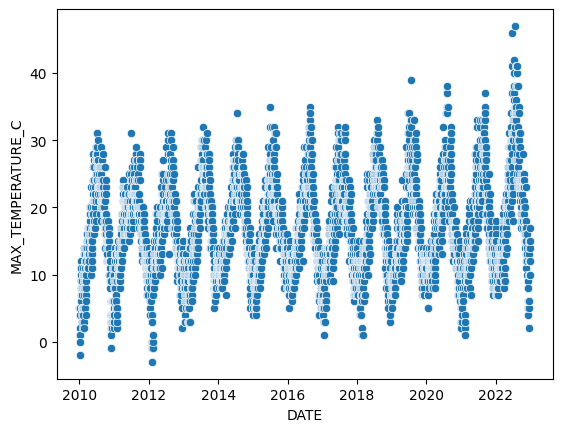

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(x="DATE" , y= "MAX_TEMPERATURE_C", data= df_weather )


Find appropriate dataviz to answer to this question :

Which year had the best weather? Are years very different or not ?


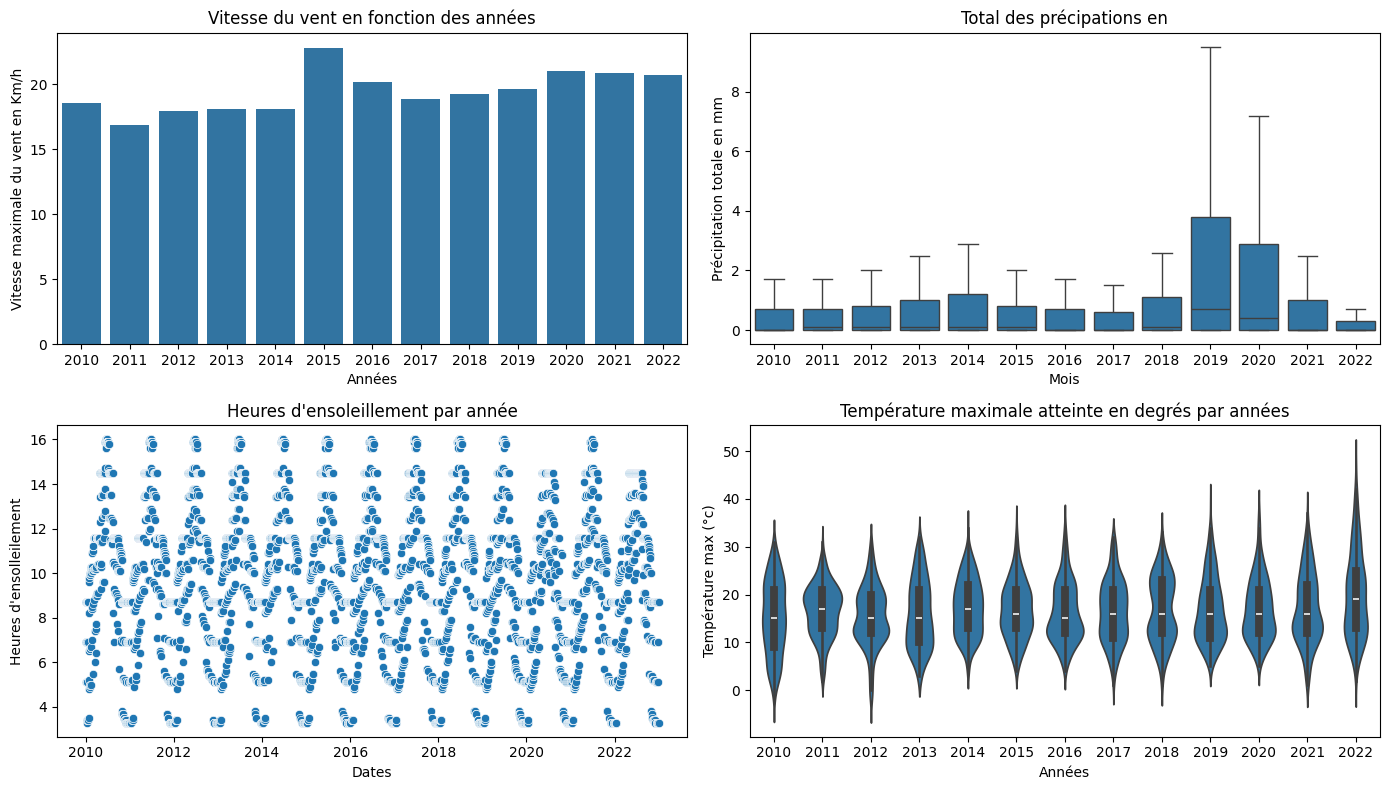

In [51]:
df_weather["YEAR"] = df_weather["DATE"].dt.year

fig, ax = plt.subplots(2, 2, figsize=(14, 8))

#Graph 1

sns.barplot(x='YEAR', y='WINDSPEED_MAX_KMH', data=df_weather,errorbar=None,ax=ax[0, 0])  # ci=None ou errorbar=None supprime les barres d'erreur
ax[0,0].set_title("Vitesse du vent en fonction des années")
ax[0,0].set_xlabel("Années")
ax[0,0].set_ylabel("Vitesse maximale du vent en Km/h")


#Graph 2

sns.boxplot(x='YEAR', y='PRECIP_TOTAL_DAY_MM', data=df_weather,showfliers=False,ax=ax[0, 1])
ax[0,1].set_title("Total des précipations en")
ax[0,1].set_xlabel("Mois")
ax[0,1].set_ylabel("Précipitation totale en mm")


#Graph 3

sns.scatterplot(x='DATE', y='SUNHOUR', data=df_weather ,ax=ax[1, 0])
ax[1,0].set_title("Heures d'ensoleillement par année")
ax[1,0].set_xlabel("Dates")
ax[1,0].set_ylabel("Heures d'ensolleilement")


#Graph 4

sns.violinplot(x='YEAR', y='MAX_TEMPERATURE_C', data=df_weather,ax=ax[1, 1])
ax[1,1].set_title("Température maximale atteinte en degrés par années")
ax[1,1].set_xlabel("Années")
ax[1,1].set_ylabel("Température max (°c)")


plt.tight_layout()

Quelles années semblent avoir bénéficié des meilleures conditions météo ? Pour quelles raisons ?

Les années 2011,2012,2013,2014,2016,2017,2018 :
- Vent modéré (pas de pics extrêmes)
- Précipitations globalement faibles à modérées
- Ensoleillement assez élevé et régulier
- Températures max stables, sans extrêmes violents